# Controllers: from a target to motor torque

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/3_robot_learning/02_controllers.ipynb) &nbsp; Guide note: [guide-robotics-fundamentals](https://www.matthewwnuk.com/guide-robotics-fundamentals.html)

A learned policy outputs targets tens of times a second. A controller underneath turns each target into
motor torque hundreds of times a second, and its settings decide what an action physically does.
This notebook simulates one joint to show PID control, gravity compensation, and what stiffness means
when the robot touches something.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from guide_utils import style
style.use(); dt = 0.001

## PID on a joint that carries a load

The joint has unit inertia, some friction and a constant load, such as its own weight.
The command is a step from 0 to 1.

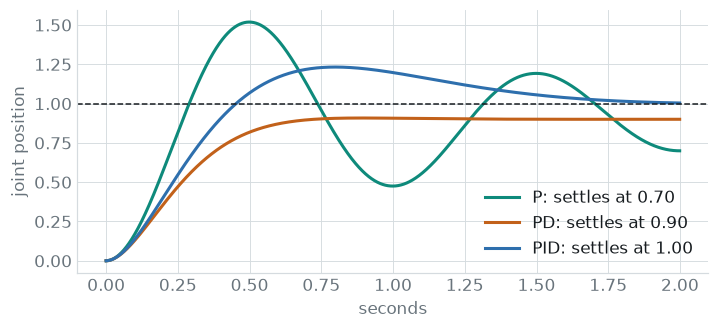

In [3]:
def simulate(kp, ki, kd, load=4.0, compensate=0.0, seconds=2.0):
    x = v = integral = 0.0; out = []
    for _ in range(int(seconds / dt)):
        e = 1.0 - x; integral += e * dt; u = kp * e + ki * integral - kd * v + compensate
        a = u - load - 1.5 * v; v += a * dt; x += v * dt; out.append(x)
    return np.array(out)

t = np.arange(0, 2.0, dt); plt.figure(figsize=(7.4, 3.1))
for name, gains in (("P", (40, 0, 0)), ("PD", (40, 0, 9)), ("PID", (40, 60, 9))):
    y = simulate(*gains); plt.plot(t, y, label=f"{name}: settles at {y[-1]:.2f}")
plt.axhline(1, color=style.INK, ls="--", lw=1); plt.xlabel("seconds"); plt.ylabel("joint position"); plt.legend(); plt.show()

Proportional control alone oscillates. A derivative term damps it and leaves a steady error, because a
constant push is needed to hold the load and that needs a constant error. The integral term removes it.

## Gravity compensation

If the load is known, add it to the command and the feedback terms no longer have to fight it.

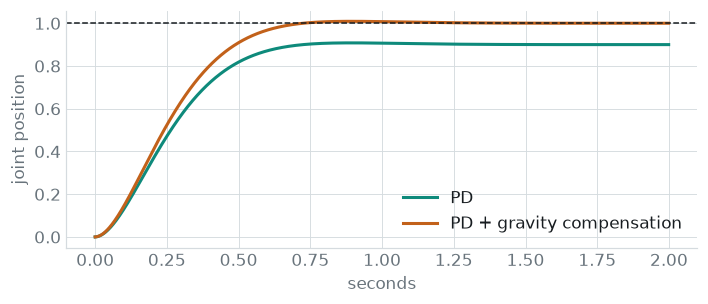

In [4]:
plt.figure(figsize=(7.4, 2.8)); plt.plot(t, simulate(40, 0, 9), label="PD"); plt.plot(t, simulate(40, 0, 9, compensate=4.0), label="PD + gravity compensation")
plt.axhline(1, color=style.INK, ls="--", lw=1); plt.xlabel("seconds"); plt.ylabel("joint position"); plt.legend(); plt.show()

## Stiffness and contact

An impedance controller makes the joint behave as a spring and damper around its target:
force = K (target - position) - D velocity. Command a position just past a rigid surface and see what
each stiffness does.

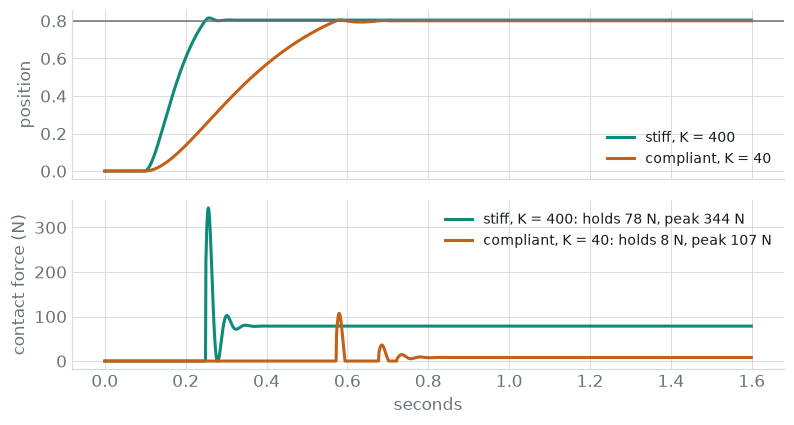

In [5]:
def contact(K, wall=0.8, seconds=1.6):
    D = 2 * np.sqrt(K); x = v = 0.0; X, Fc = [], []
    for i in range(int(seconds / dt)):
        target = 1.0 if i * dt >= 0.1 else 0.0; f_wall = max(20000.0 * (x - wall) + 60 * v, 0.0) if x > wall else 0.0
        v += (K * (target - x) - D * v - f_wall) * dt; x += v * dt; X.append(x); Fc.append(f_wall)
    return np.array(X), np.array(Fc)

t = np.arange(0, 1.6, dt); fig, ax = plt.subplots(2, 1, figsize=(7.4, 4), sharex=True)
for name, K in (("stiff, K = 400", 400.0), ("compliant, K = 40", 40.0)):
    X, Fc = contact(K); ax[0].plot(t, X, label=name); ax[1].plot(t, Fc, label=f"{name}: holds {Fc[-1]:.0f} N, peak {Fc.max():.0f} N")
ax[0].axhline(0.8, color=style.MUTED, lw=1); ax[0].set_ylabel("position"); ax[0].legend(fontsize=9); ax[1].set_ylabel("contact force (N)"); ax[1].set_xlabel("seconds"); ax[1].legend(fontsize=9); plt.tight_layout(); plt.show()

Both controllers received the same command. The steady force is stiffness times the remaining error:
K x 0.2. That one number decides whether a contact is gentle, and it is why demonstrations recorded with
one controller do not replay correctly through another.

## Commanded against reached

The position the robot was told to go to and the position it reached are different signals. A dataset
may store either.

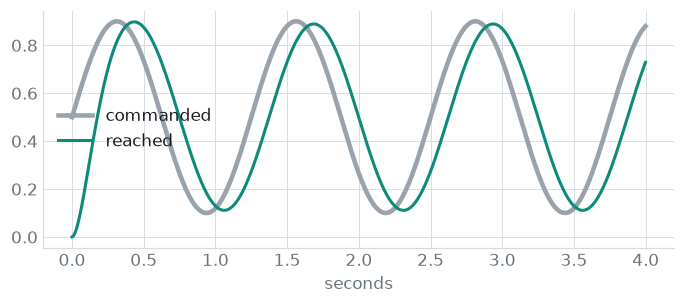

the reached position lags the command by about 123 ms and has 97% of its amplitude


In [6]:
target = 0.5 + 0.4 * np.sin(2 * np.pi * 0.8 * np.arange(0, 4, dt)); x = v = 0.0; reached = []
for tg in target:
    v += (150 * (tg - x) - 18 * v) * dt; x += v * dt; reached.append(x)
tt = np.arange(0, 4, dt); plt.figure(figsize=(7.4, 2.8)); plt.plot(tt, target, color=style.GREY, lw=3, label="commanded"); plt.plot(tt, reached, color=style.TEAL, label="reached"); plt.xlabel("seconds"); plt.legend(); plt.show()
lag = np.argmax(np.correlate(np.array(reached) - 0.5, target - 0.5, "full")) - (len(target) - 1); print(f"the reached position lags the command by about {lag * dt * 1000:.0f} ms and has {np.ptp(reached[2000:]) / np.ptp(target[2000:]):.0%} of its amplitude")

## Things to try

- Raise `kp` until the PD controller becomes unstable. How does the limit depend on `dt`?
- Add a 20 ms delay between measuring the position and applying the command.
- In `contact`, lower the wall's stiffness to model a soft object. Which controller notices the difference?